This project aims to group countries with similar military capabilities using clustering techniques. The dataset contains 138 countries and includes indicators related to air, land, and naval forces, defense spending, manpower, natural resources, logistics, and geography. Following data cleaning and preprocessing, clustering methods will be applied to identify patterns across countries. The resulting clusters will be analyzed to understand the characteristics that distinguish different military capability profiles.

In [1]:
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


### 1.EDA

In [2]:
df = pd.read_excel("World military power.xlsx")
df.head()

,2020 ranking,Unnamed: 1,Airforce Strength,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,Unnamed: 50,Unnamed: 51,Geography,Unnamed: 53,Unnamed: 54,Unnamed: 55,Unnamed: 56,Unnamed: 57,Unnamed: 58,Unnamed: 59
0,Military Strength,Military Strength Power Index,Aircraft Strength,Aircraft Strength value,Fighter/Interceptor Strength,Fighter/Interceptor Strength value,Attack Aircraft Strength,Attack Aircraft Strength value,Transport Aircraft Fleet Strength,Transport Aircraft Fleet Strength value,...,Total Population,Total Population value,Total Square Land Area,Total Square Land Area value,Total Coastline Coverage,Total Coastline Coverage value,Total Waterway Coverage,Total Waterway Coverage value,Total Border Coverage,Total Border Coverage value
1,Afghanistan,1.3444,Afghanistan,260,Afghanistan,0,Afghanistan,25,Afghanistan,30,...,Afghanistan,"3,49,40,837",Afghanistan,"6,52,230",Afghanistan,0,Afghanistan,1200,Afghanistan,5987
2,Albania,2.3137,Albania,19,Albania,0,Albania,0,Albania,0,...,Albania,"30,57,220",Albania,28748,Albania,362,Albania,41,Albania,691
3,Algeria,0.4659,Algeria,551,Algeria,103,Algeria,22,Algeria,59,...,Algeria,"4,16,57,488",Algeria,"23,81,741",Algeria,998,Algeria,0,Algeria,6734
4,Angola,0.8379,Angola,295,Angola,72,Angola,18,Angola,30,...,Angola,"3,03,55,880",Angola,"12,46,700",Angola,1600,Angola,1300,Angola,5369


In [3]:
df = pd.read_excel("World military power.xlsx", header=1)
df.head()

,Military Strength,Military Strength Power Index,Aircraft Strength,Aircraft Strength value,Fighter/Interceptor Strength,Fighter/Interceptor Strength value,Attack Aircraft Strength,Attack Aircraft Strength value,Transport Aircraft Fleet Strength,Transport Aircraft Fleet Strength value,...,Total Population,Total Population value,Total Square Land Area,Total Square Land Area value,Total Coastline Coverage,Total Coastline Coverage value,Total Waterway Coverage,Total Waterway Coverage value,Total Border Coverage,Total Border Coverage value
0,Afghanistan,1.3444,Afghanistan,260,Afghanistan,0,Afghanistan,25,Afghanistan,30,...,Afghanistan,"3,49,40,837",Afghanistan,"6,52,230",Afghanistan,0,Afghanistan,1200,Afghanistan,5987.0
1,Albania,2.3137,Albania,19,Albania,0,Albania,0,Albania,0,...,Albania,"30,57,220",Albania,28748,Albania,362,Albania,41,Albania,691.0
2,Algeria,0.4659,Algeria,551,Algeria,103,Algeria,22,Algeria,59,...,Algeria,"4,16,57,488",Algeria,"23,81,741",Algeria,998,Algeria,0,Algeria,6734.0
3,Angola,0.8379,Angola,295,Angola,72,Angola,18,Angola,30,...,Angola,"3,03,55,880",Angola,"12,46,700",Angola,1600,Angola,1300,Angola,5369.0
4,Argentina,0.6521,Argentina,227,Argentina,24,Argentina,7,Argentina,9,...,Argentina,"4,46,94,198",Argentina,"27,80,400",Argentina,4989,Argentina,11000,Argentina,11968.0


In [4]:
df.shape

(138, 60)

In [5]:
df.isnull().sum()

Military Strength                           0
Military Strength Power Index               0
Aircraft Strength                           0
Aircraft Strength value                     0
Fighter/Interceptor Strength                0
Fighter/Interceptor Strength value          0
Attack Aircraft Strength                    0
Attack Aircraft Strength value              0
Transport Aircraft Fleet Strength           0
Transport Aircraft Fleet Strength value     0
Trainer Aircraft Fleet                      0
Trainer Aircraft Fleet value                0
Helicopter Fleet Strength                   0
Helicopter Fleet Strength value             0
Attack Helicopter Fleet Strength            0
Attack Helicopter Fleet Strength value      0
Tank Strength                               0
Tank Strength value                         0
AFV/APC Strength                            0
AFV/APC Strength value                      0
Self-Propelled Artillery Strength           0
Self-Propelled Artillery Strength 

In [6]:
df.columns

Index(['Military Strength', 'Military Strength Power Index',
       'Aircraft Strength', 'Aircraft Strength value',
       'Fighter/Interceptor Strength', 'Fighter/Interceptor Strength value',
       'Attack Aircraft Strength', 'Attack Aircraft Strength value',
       'Transport Aircraft Fleet Strength',
       'Transport Aircraft Fleet Strength value', 'Trainer Aircraft Fleet',
       'Trainer Aircraft Fleet value', 'Helicopter Fleet Strength',
       'Helicopter Fleet Strength value', 'Attack Helicopter Fleet Strength',
       'Attack Helicopter Fleet Strength value', 'Tank Strength',
       'Tank Strength value', 'AFV/APC Strength', 'AFV/APC Strength value',
       'Self-Propelled Artillery Strength',
       'Self-Propelled Artillery Strength value', 'Towed Artillery Strength',
       'Towed Artillery Strength value', 'Rocket Projector Strength',
       'Rocket Projector Strength value', 'Navy Fleet Strengths',
       'Navy Fleet Strengths value', 'Aircraft Carrier Fleet Strength',


In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.select_dtypes(include=["object", "string"]).head()

,Military Strength,Aircraft Strength,Fighter/Interceptor Strength,Attack Aircraft Strength,Transport Aircraft Fleet Strength,Trainer Aircraft Fleet,Helicopter Fleet Strength,Attack Helicopter Fleet Strength,Tank Strength,AFV/APC Strength,...,Available Manpower value,Total Population,Total Population value,Total Square Land Area,Total Square Land Area value,Total Coastline Coverage,Total Coastline Coverage value,Total Waterway Coverage,Total Waterway Coverage value,Total Border Coverage
0,Afghanistan,Afghanistan,Afghanistan,Afghanistan,Afghanistan,Afghanistan,Afghanistan,Afghanistan,Afghanistan,Afghanistan,...,"1,43,25,743",Afghanistan,"3,49,40,837",Afghanistan,"6,52,230",Afghanistan,0,Afghanistan,1200,Afghanistan
1,Albania,Albania,Albania,Albania,Albania,Albania,Albania,Albania,Albania,Albania,...,"15,19,438",Albania,"30,57,220",Albania,28748,Albania,362,Albania,41,Albania
2,Algeria,Algeria,Algeria,Algeria,Algeria,Algeria,Algeria,Algeria,Algeria,Algeria,...,"2,07,41,263",Algeria,"4,16,57,488",Algeria,"23,81,741",Algeria,998,Algeria,0,Algeria
3,Angola,Angola,Angola,Angola,Angola,Angola,Angola,Angola,Angola,Angola,...,"62,44,205",Angola,"3,03,55,880",Angola,"12,46,700",Angola,1600,Angola,1300,Angola
4,Argentina,Argentina,Argentina,Argentina,Argentina,Argentina,Argentina,Argentina,Argentina,Argentina,...,"2,01,79,430",Argentina,"4,46,94,198",Argentina,"27,80,400",Argentina,4989,Argentina,11000,Argentina


In [9]:
ulke_sutunlari = df.columns[::2]
df[ulke_sutunlari].head()

,Military Strength,Aircraft Strength,Fighter/Interceptor Strength,Attack Aircraft Strength,Transport Aircraft Fleet Strength,Trainer Aircraft Fleet,Helicopter Fleet Strength,Attack Helicopter Fleet Strength,Tank Strength,AFV/APC Strength,...,Airport Totals,Oil Production,Oil Consumption,Proven Oil Reserves,Available Manpower,Total Population,Total Square Land Area,Total Coastline Coverage,Total Waterway Coverage,Total Border Coverage
0,Afghanistan,Afghanistan,Afghanistan,Afghanistan,Afghanistan,Afghanistan,Afghanistan,Afghanistan,Afghanistan,Afghanistan,...,Afghanistan,Afghanistan,Afghanistan,Afghanistan,Afghanistan,Afghanistan,Afghanistan,Afghanistan,Afghanistan,Afghanistan
1,Albania,Albania,Albania,Albania,Albania,Albania,Albania,Albania,Albania,Albania,...,Albania,Albania,Albania,Albania,Albania,Albania,Albania,Albania,Albania,Albania
2,Algeria,Algeria,Algeria,Algeria,Algeria,Algeria,Algeria,Algeria,Algeria,Algeria,...,Algeria,Algeria,Algeria,Algeria,Algeria,Algeria,Algeria,Algeria,Algeria,Algeria
3,Angola,Angola,Angola,Angola,Angola,Angola,Angola,Angola,Angola,Angola,...,Angola,Angola,Angola,Angola,Angola,Angola,Angola,Angola,Angola,Angola
4,Argentina,Argentina,Argentina,Argentina,Argentina,Argentina,Argentina,Argentina,Argentina,Argentina,...,Argentina,Argentina,Argentina,Argentina,Argentina,Argentina,Argentina,Argentina,Argentina,Argentina


In [10]:
ulke_df = df[ulke_sutunlari]
referans = ulke_df.iloc[:, 0]

In [11]:
esit = ulke_df.eq(referans, axis=0) | (
    ulke_df.isna().mul(referans.isna(), axis=0)
)


In [12]:
farkli_satirlar = ~esit.all(axis=1)
ulke_df.loc[farkli_satirlar]

,Military Strength,Aircraft Strength,Fighter/Interceptor Strength,Attack Aircraft Strength,Transport Aircraft Fleet Strength,Trainer Aircraft Fleet,Helicopter Fleet Strength,Attack Helicopter Fleet Strength,Tank Strength,AFV/APC Strength,...,Airport Totals,Oil Production,Oil Consumption,Proven Oil Reserves,Available Manpower,Total Population,Total Square Land Area,Total Coastline Coverage,Total Waterway Coverage,Total Border Coverage
5,Armenia,Armenia,Armenia,Armenia,Armenia,Armenia,Armenia,Armenia,Armenia,Armenia,...,Armenia,Armenia,Armenia,Armenia,Armenia,Armenia,Armenia,NaN,Armenia,Armenia
6,Australia,Australia,Australia,Australia,Australia,Australia,Australia,Australia,Australia,Australia,...,Australia,Australia,Australia,Australia,Australia,Australia,Australia,Australia,Australia,NaN
7,Austria,Austria,Austria,Austria,Austria,Austria,Austria,Austria,Austria,Austria,...,Austria,Austria,Austria,Austria,Austria,Austria,Austria,NaN,Austria,Austria
9,Bahrain,Bahrain,Bahrain,Bahrain,Bahrain,Bahrain,Bahrain,Bahrain,Bahrain,Bahrain,...,Bahrain,Bahrain,Bahrain,Bahrain,Bahrain,Bahrain,Bahrain,Bahrain,Bahrain,NaN
11,Belarus,Belarus,Belarus,Belarus,Belarus,Belarus,Belarus,Belarus,Belarus,Belarus,...,Belarus,Belarus,Belarus,Belarus,Belarus,Belarus,Belarus,NaN,Belarus,Belarus
13,Bhutan,Bhutan,Bhutan,Bhutan,Bhutan,Bhutan,Bhutan,Bhutan,Bhutan,Bhutan,...,Bhutan,Bhutan,Bhutan,Bhutan,Bhutan,Bhutan,Bhutan,NaN,Bhutan,Bhutan
14,Bolivia,Bolivia,Bolivia,Bolivia,Bolivia,Bolivia,Bolivia,Bolivia,Bolivia,Bolivia,...,Bolivia,Bolivia,Bolivia,Bolivia,Bolivia,Bolivia,Bolivia,NaN,Bolivia,Bolivia
16,Botswana,Botswana,Botswana,Botswana,Botswana,Botswana,Botswana,Botswana,Botswana,Botswana,...,Botswana,Botswana,Botswana,Botswana,Botswana,Botswana,Botswana,NaN,Botswana,Botswana
19,Burkina Faso,Burkina Faso,Burkina Faso,Burkina Faso,Burkina Faso,Burkina Faso,Burkina Faso,Burkina Faso,Burkina Faso,Burkina Faso,...,Burkina Faso,Burkina Faso,Burkina Faso,Burkina Faso,Burkina Faso,Burkina Faso,Burkina Faso,NaN,Burkina Faso,Burkina Faso
23,Central African Republic,Central African Republic,Central African Republic,Central African Republic,Central African Republic,Central African Republic,Central African Republic,Central African Republic,Central African Republic,Central African Republic,...,Central African Republic,Central African Republic,Central African Republic,Central African Republic,Central African Republic,Central African Republic,Central African Republic,NaN,Central African Republic,Central African Republic


In [13]:
pd.set_option("display.max_columns", None)

df.loc[[110, 111]]

,Military Strength,Military Strength Power Index,Aircraft Strength,Aircraft Strength value,Fighter/Interceptor Strength,Fighter/Interceptor Strength value,Attack Aircraft Strength,Attack Aircraft Strength value,Transport Aircraft Fleet Strength,Transport Aircraft Fleet Strength value,Trainer Aircraft Fleet,Trainer Aircraft Fleet value,Helicopter Fleet Strength,Helicopter Fleet Strength value,Attack Helicopter Fleet Strength,Attack Helicopter Fleet Strength value,Tank Strength,Tank Strength value,AFV/APC Strength,AFV/APC Strength value,Self-Propelled Artillery Strength,Self-Propelled Artillery Strength value,Towed Artillery Strength,Towed Artillery Strength value,Rocket Projector Strength,Rocket Projector Strength value,Navy Fleet Strengths,Navy Fleet Strengths value,Aircraft Carrier Fleet Strength,Aircraft Carrier Fleet Strength value,Submarine Fleet Strength,Submarine Fleet Strength value,Destroyer Fleet Strength,Destroyer Fleet Strength value,Frigate Fleet Strength,Frigate Fleet Strength value,defense spending budget,defense spending budget value,External Debt,External Debt value,Airport Totals,Airport Totals value,Oil Production,Oil Production value,Oil Consumption,Oil Consumption value,Proven Oil Reserves,Proven Oil Reserves value,Available Manpower,Available Manpower value,Total Population,Total Population value,Total Square Land Area,Total Square Land Area value,Total Coastline Coverage,Total Coastline Coverage value,Total Waterway Coverage,Total Waterway Coverage value,Total Border Coverage,Total Border Coverage value
110,South Korea,0.1509,South Korea,1649,South Korea,414,South Korea,71,South Korea,41,South Korea,298,South Korea,803,South Korea,112,South Korea,2614,South Korea,14000,South Korea,3040,South Korea,3854,South Korea,575,South Korea,234.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,South Korea,"44,00,00,00,000",South Korea,"3,84,60,00,00,000",South Korea,111,South Korea,0,South Korea,"28,00,000",South Korea,0,South Korea,"2,57,09,049",South Korea,"5,14,18,097",South Korea,99720,South Korea,2413,South Korea,1600,South Korea,237.0
111,South Sudan,2.3501,South Sudan,19,South Sudan,0,South Sudan,0,South Sudan,2,South Sudan,0,South Sudan,17,South Sudan,6,South Sudan,110,South Sudan,200,South Sudan,24,South Sudan,0,South Sudan,14,South Sudan,0.0,South Korea,2.0,South Korea,22.0,South Korea,12.0,South Korea,18.0,South Sudan,"8,00,00,000",South Sudan,"2,25,00,00,000",South Sudan,85,South Sudan,"1,50,200",South Sudan,60000,South Sudan,"3,75,00,00,000",South Sudan,"52,45,155",South Sudan,"1,02,04,581",South Sudan,"6,44,329",NaN,NaN,South Sudan,0,South Sudan,6018.0


South Sudan, a landlocked country, is listed as having 22 submarines. These figures actually belong to South Korea.

In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 138 entries, 0 to 137
Data columns (total 60 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   Military Strength                        138 non-null    str    
 1   Military Strength Power Index            138 non-null    float64
 2   Aircraft Strength                        138 non-null    str    
 3   Aircraft Strength value                  138 non-null    int64  
 4   Fighter/Interceptor Strength             138 non-null    str    
 5   Fighter/Interceptor Strength value       138 non-null    int64  
 6   Attack Aircraft Strength                 138 non-null    str    
 7   Attack Aircraft Strength value           138 non-null    int64  
 8   Transport Aircraft Fleet Strength        138 non-null    str    
 9   Transport Aircraft Fleet Strength value  138 non-null    int64  
 10  Trainer Aircraft Fleet                   138 non-null    str 

### 2. Feature Engineering

In [15]:
df.columns

Index(['Military Strength', 'Military Strength Power Index',
       'Aircraft Strength', 'Aircraft Strength value',
       'Fighter/Interceptor Strength', 'Fighter/Interceptor Strength value',
       'Attack Aircraft Strength', 'Attack Aircraft Strength value',
       'Transport Aircraft Fleet Strength',
       'Transport Aircraft Fleet Strength value', 'Trainer Aircraft Fleet',
       'Trainer Aircraft Fleet value', 'Helicopter Fleet Strength',
       'Helicopter Fleet Strength value', 'Attack Helicopter Fleet Strength',
       'Attack Helicopter Fleet Strength value', 'Tank Strength',
       'Tank Strength value', 'AFV/APC Strength', 'AFV/APC Strength value',
       'Self-Propelled Artillery Strength',
       'Self-Propelled Artillery Strength value', 'Towed Artillery Strength',
       'Towed Artillery Strength value', 'Rocket Projector Strength',
       'Rocket Projector Strength value', 'Navy Fleet Strengths',
       'Navy Fleet Strengths value', 'Aircraft Carrier Fleet Strength',


In [16]:
naval=['Aircraft Carrier Fleet Strength', 'Submarine Fleet Strength', 'Destroyer Fleet Strength', 'Frigate Fleet Strength']
naval_val=['Aircraft Carrier Fleet Strength value', 'Submarine Fleet Strength value', 'Destroyer Fleet Strength value', 'Frigate Fleet Strength value']
df.loc[110, naval + naval_val] = df.loc[111, naval + naval_val].values
df.loc[111, naval] = 'South Sudan'
df.loc[111, naval_val] = 0          

In [17]:
df.insert(0, "Country",df["Military Strength"])

In [18]:
df.drop(columns = df.iloc[:,1:60:2], inplace = True)

In [19]:
df.head()

,Country,Military Strength Power Index,Aircraft Strength value,Fighter/Interceptor Strength value,Attack Aircraft Strength value,Transport Aircraft Fleet Strength value,Trainer Aircraft Fleet value,Helicopter Fleet Strength value,Attack Helicopter Fleet Strength value,Tank Strength value,AFV/APC Strength value,Self-Propelled Artillery Strength value,Towed Artillery Strength value,Rocket Projector Strength value,Navy Fleet Strengths value,Aircraft Carrier Fleet Strength value,Submarine Fleet Strength value,Destroyer Fleet Strength value,Frigate Fleet Strength value,defense spending budget value,External Debt value,Airport Totals value,Oil Production value,Oil Consumption value,Proven Oil Reserves value,Available Manpower value,Total Population value,Total Square Land Area value,Total Coastline Coverage value,Total Waterway Coverage value,Total Border Coverage value
0,Afghanistan,1.3444,260,0,25,30,0,187,0,0,1062,0,176,50,0.0,0.0,0.0,0.0,0.0,"12,00,00,00,000","2,84,00,00,000",43,0,5500,0,"1,43,25,743","3,49,40,837","6,52,230",0,1200,5987.0
1,Albania,2.3137,19,0,0,0,0,19,0,0,467,0,0,0,38.0,0.0,0.0,0.0,0.0,"25,00,00,000","9,50,50,00,000",4,16000,42500,"16,83,00,000","15,19,438","30,57,220",28748,362,41,691.0
2,Algeria,0.4659,551,103,22,59,87,257,45,880,7361,320,240,316,201.0,0.0,6.0,0.0,5.0,"13,00,00,00,000","6,26,00,00,000",157,"13,06,000","3,25,000","12,20,00,00,000","2,07,41,263","4,16,57,488","23,81,741",998,0,6734.0
3,Angola,0.8379,295,72,18,30,47,126,15,379,595,28,357,115,57.0,0.0,0.0,0.0,0.0,"7,00,00,00,000","42,08,00,00,000",176,"16,66,000",82300,"8,27,30,00,000","62,44,205","3,03,55,880","12,46,700",1600,1300,5369.0
4,Argentina,0.6521,227,24,7,9,64,100,0,370,739,83,172,26,49.0,0.0,2.0,4.0,0.0,"4,20,00,00,000","2,14,90,00,00,000",1138,"4,79,400","6,85,000","2,18,50,00,000","2,01,79,430","4,46,94,198","27,80,400",4989,11000,11968.0


In [20]:
df.shape

(138, 31)

In [21]:
df.isnull().sum().loc[lambda x: x > 0]

Navy Fleet Strengths value               14
Aircraft Carrier Fleet Strength value    22
Submarine Fleet Strength value           22
Destroyer Fleet Strength value           22
Frigate Fleet Strength value             22
Total Coastline Coverage value           29
Total Border Coverage value               9
dtype: int64

In [22]:
df.set_index("Country").isna().loc[lambda x: x.any(axis=1), lambda x: x.any(axis=0)]

,Navy Fleet Strengths value,Aircraft Carrier Fleet Strength value,Submarine Fleet Strength value,Destroyer Fleet Strength value,Frigate Fleet Strength value,Total Coastline Coverage value,Total Border Coverage value
Country,,,,,,,
Armenia,False,True,True,True,True,True,False
Australia,False,False,False,False,False,False,True
Austria,False,True,True,True,True,True,False
Bahrain,False,False,False,False,False,False,True
Belarus,False,True,True,True,True,True,False
Bhutan,False,True,True,True,True,True,False
Bolivia,False,False,False,False,False,True,False
Botswana,True,True,True,True,True,True,False
Burkina Faso,True,True,True,True,True,True,False


The missing values in this dataset are structural rather than random. They don't stand for unknown data; they mean the feature does not exist for that country:

- **Naval and coastline variables** (Navy Fleet Strength, Aircraft Carriers, Submarines, Destroyers, Frigates, Coastline) are missing for **landlocked countries** (e.g. Chad, Hungary, Switzerland). A country without access to the sea has no coastline and no naval fleet.
- **Border length** is missing for **island nations** (e.g. Japan, Australia, New Zealand, Singapore), which share no land border with any other country.

The data is internally consistent with this interpretation. For example, Armenia has a total navy strength of 0, while its naval subcategories are missing. A country with no ships cannot have submarines or frigates.

Mean or median imputation would therefore be misleading. It would give landlocked countries a fictional navy (about 5 submarines and 85 ships on average), which could place them in the wrong cluster. For this reason, these missing values are filled with **0**, which represents their true value.

In [23]:
df = df.fillna(0)

In [24]:
df.select_dtypes(include=["object", "string"]).columns

Index(['Country', 'defense spending budget value', 'External Debt value',
       'Oil Production value', 'Oil Consumption value',
       'Proven Oil Reserves value', 'Available Manpower value',
       'Total Population value', 'Total Square Land Area value',
       'Total Coastline Coverage value', 'Total Waterway Coverage value'],
      dtype='str')

In [25]:
cols=df.select_dtypes(include=["object", "string"]).drop(columns="Country")

In [26]:
for col in cols:
    df[col] = pd.to_numeric(df[col].astype(str).str.replace(",", "", regex=False))

In [27]:
cols.head()

,defense spending budget value,External Debt value,Oil Production value,Oil Consumption value,Proven Oil Reserves value,Available Manpower value,Total Population value,Total Square Land Area value,Total Coastline Coverage value,Total Waterway Coverage value
0,"12,00,00,00,000","2,84,00,00,000",0,5500,0,"1,43,25,743","3,49,40,837","6,52,230",0,1200
1,"25,00,00,000","9,50,50,00,000",16000,42500,"16,83,00,000","15,19,438","30,57,220",28748,362,41
2,"13,00,00,00,000","6,26,00,00,000","13,06,000","3,25,000","12,20,00,00,000","2,07,41,263","4,16,57,488","23,81,741",998,0
3,"7,00,00,00,000","42,08,00,00,000","16,66,000",82300,"8,27,30,00,000","62,44,205","3,03,55,880","12,46,700",1600,1300
4,"4,20,00,00,000","2,14,90,00,00,000","4,79,400","6,85,000","2,18,50,00,000","2,01,79,430","4,46,94,198","27,80,400",4989,11000


In [28]:
cols.dtypes

defense spending budget value        str
External Debt value                  str
Oil Production value              object
Oil Consumption value             object
Proven Oil Reserves value         object
Available Manpower value             str
Total Population value               str
Total Square Land Area value      object
Total Coastline Coverage value    object
Total Waterway Coverage value     object
dtype: object

In [29]:
print(cols.dtypes.value_counts())

object    6
str       4
Name: count, dtype: int64


In [30]:
assert cols.isnull().sum().sum() == 0

In [31]:
df.columns

Index(['Country', 'Military Strength Power Index', 'Aircraft Strength value',
       'Fighter/Interceptor Strength value', 'Attack Aircraft Strength value',
       'Transport Aircraft Fleet Strength value',
       'Trainer Aircraft Fleet value', 'Helicopter Fleet Strength value',
       'Attack Helicopter Fleet Strength value', 'Tank Strength value',
       'AFV/APC Strength value', 'Self-Propelled Artillery Strength value',
       'Towed Artillery Strength value', 'Rocket Projector Strength value',
       'Navy Fleet Strengths value', 'Aircraft Carrier Fleet Strength value',
       'Submarine Fleet Strength value', 'Destroyer Fleet Strength value',
       'Frigate Fleet Strength value', 'defense spending budget value',
       'External Debt value', 'Airport Totals value', 'Oil Production value',
       'Oil Consumption value', 'Proven Oil Reserves value',
       'Available Manpower value', 'Total Population value',
       'Total Square Land Area value', 'Total Coastline Coverage value

In [32]:
df.shape

(138, 31)

In [33]:
df.corr(numeric_only=True)

,Military Strength Power Index,Aircraft Strength value,Fighter/Interceptor Strength value,Attack Aircraft Strength value,Transport Aircraft Fleet Strength value,Trainer Aircraft Fleet value,Helicopter Fleet Strength value,Attack Helicopter Fleet Strength value,Tank Strength value,AFV/APC Strength value,Self-Propelled Artillery Strength value,Towed Artillery Strength value,Rocket Projector Strength value,Navy Fleet Strengths value,Aircraft Carrier Fleet Strength value,Submarine Fleet Strength value,Destroyer Fleet Strength value,Frigate Fleet Strength value,defense spending budget value,External Debt value,Airport Totals value,Oil Production value,Oil Consumption value,Proven Oil Reserves value,Available Manpower value,Total Population value,Total Square Land Area value,Total Coastline Coverage value,Total Waterway Coverage value,Total Border Coverage value
Military Strength Power Index,1.000000,-0.267329,-0.310888,-0.241948,-0.267104,-0.284756,-0.244545,-0.231723,-0.324300,-0.361796,-0.268935,-0.335405,-0.247800,-0.381789,-0.179344,-0.295426,-0.191655,-0.395382,-0.192424,-0.235734,-0.173362,-0.263961,-0.282414,-0.183438,-0.236737,-0.242678,-0.258779,-0.183884,-0.240222,-0.247132
Aircraft Strength value,-0.267329,1.000000,0.944492,0.860263,0.974029,0.974288,0.992802,0.964266,0.625598,0.844898,0.513687,0.566740,0.520071,0.532988,0.928195,0.685116,0.923603,0.274483,0.955621,0.800685,0.884260,0.625914,0.903431,0.125047,0.385843,0.403410,0.586455,0.152612,0.445029,0.414819
Fighter/Interceptor Strength value,-0.310888,0.944492,1.000000,0.878844,0.908768,0.886299,0.905858,0.922056,0.719875,0.932691,0.659839,0.696251,0.669376,0.669301,0.812836,0.818483,0.885775,0.495018,0.892206,0.693046,0.733474,0.622783,0.923384,0.141509,0.566067,0.570915,0.619211,0.144830,0.551287,0.486221
Attack Aircraft Strength value,-0.241948,0.860263,0.878844,1.000000,0.892666,0.762131,0.820890,0.916149,0.812318,0.871821,0.776320,0.684005,0.772270,0.634499,0.662580,0.769576,0.740852,0.347246,0.741498,0.547148,0.663088,0.731814,0.773883,0.162843,0.459166,0.465651,0.773643,0.162162,0.656929,0.608929
Transport Aircraft Fleet Strength value,-0.267104,0.974029,0.908768,0.892666,1.000000,0.927991,0.964244,0.948860,0.647605,0.818061,0.530161,0.576765,0.542214,0.525189,0.874138,0.659220,0.872472,0.258555,0.912735,0.759182,0.874719,0.668640,0.878218,0.154009,0.429612,0.449885,0.671585,0.171698,0.507041,0.513081
Trainer Aircraft Fleet value,-0.284756,0.974288,0.886299,0.762131,0.927991,1.000000,0.973744,0.909770,0.547113,0.773963,0.392221,0.495196,0.400216,0.466886,0.941525,0.596116,0.894440,0.210766,0.934795,0.813180,0.899261,0.569708,0.855577,0.123859,0.297804,0.321369,0.500443,0.158804,0.338359,0.316252
Helicopter Fleet Strength value,-0.244545,0.992802,0.905858,0.820890,0.964244,0.973744,1.000000,0.953013,0.568368,0.798437,0.453496,0.509179,0.448298,0.473208,0.948694,0.624215,0.919066,0.205886,0.958026,0.825917,0.904459,0.595627,0.877732,0.106103,0.313245,0.333446,0.537483,0.142145,0.385513,0.361978
Attack Helicopter Fleet Strength value,-0.231723,0.964266,0.922056,0.916149,0.948860,0.909770,0.953013,1.000000,0.693216,0.860358,0.640999,0.570675,0.614542,0.512729,0.861475,0.694213,0.888971,0.268084,0.894450,0.738504,0.812823,0.665574,0.846129,0.124168,0.319627,0.329679,0.648221,0.143269,0.515447,0.440390
Tank Strength value,-0.324300,0.625598,0.719875,0.812318,0.647605,0.547113,0.568368,0.693216,1.000000,0.778759,0.830509,0.805103,0.864147,0.691684,0.383508,0.764176,0.463844,0.373357,0.420121,0.258375,0.346984,0.567311,0.481247,0.146265,0.363193,0.371196,0.617159,0.119993,0.531206,0.481161
AFV/APC Strength value,-0.361796,0.844898,0.932691,0.871821,0.818061,0.773963,0.798437,0.860358,0.778759,1.000000,0.790061,0.765663,0.751266,0.696010,0.672121,0.805039,0.755552,0.553006,0.771662,0.566182,0.591883,0.683281,0.844824,0.221302,0.553925,0.549386,0.644503,0.141088,0.580005,0.501611


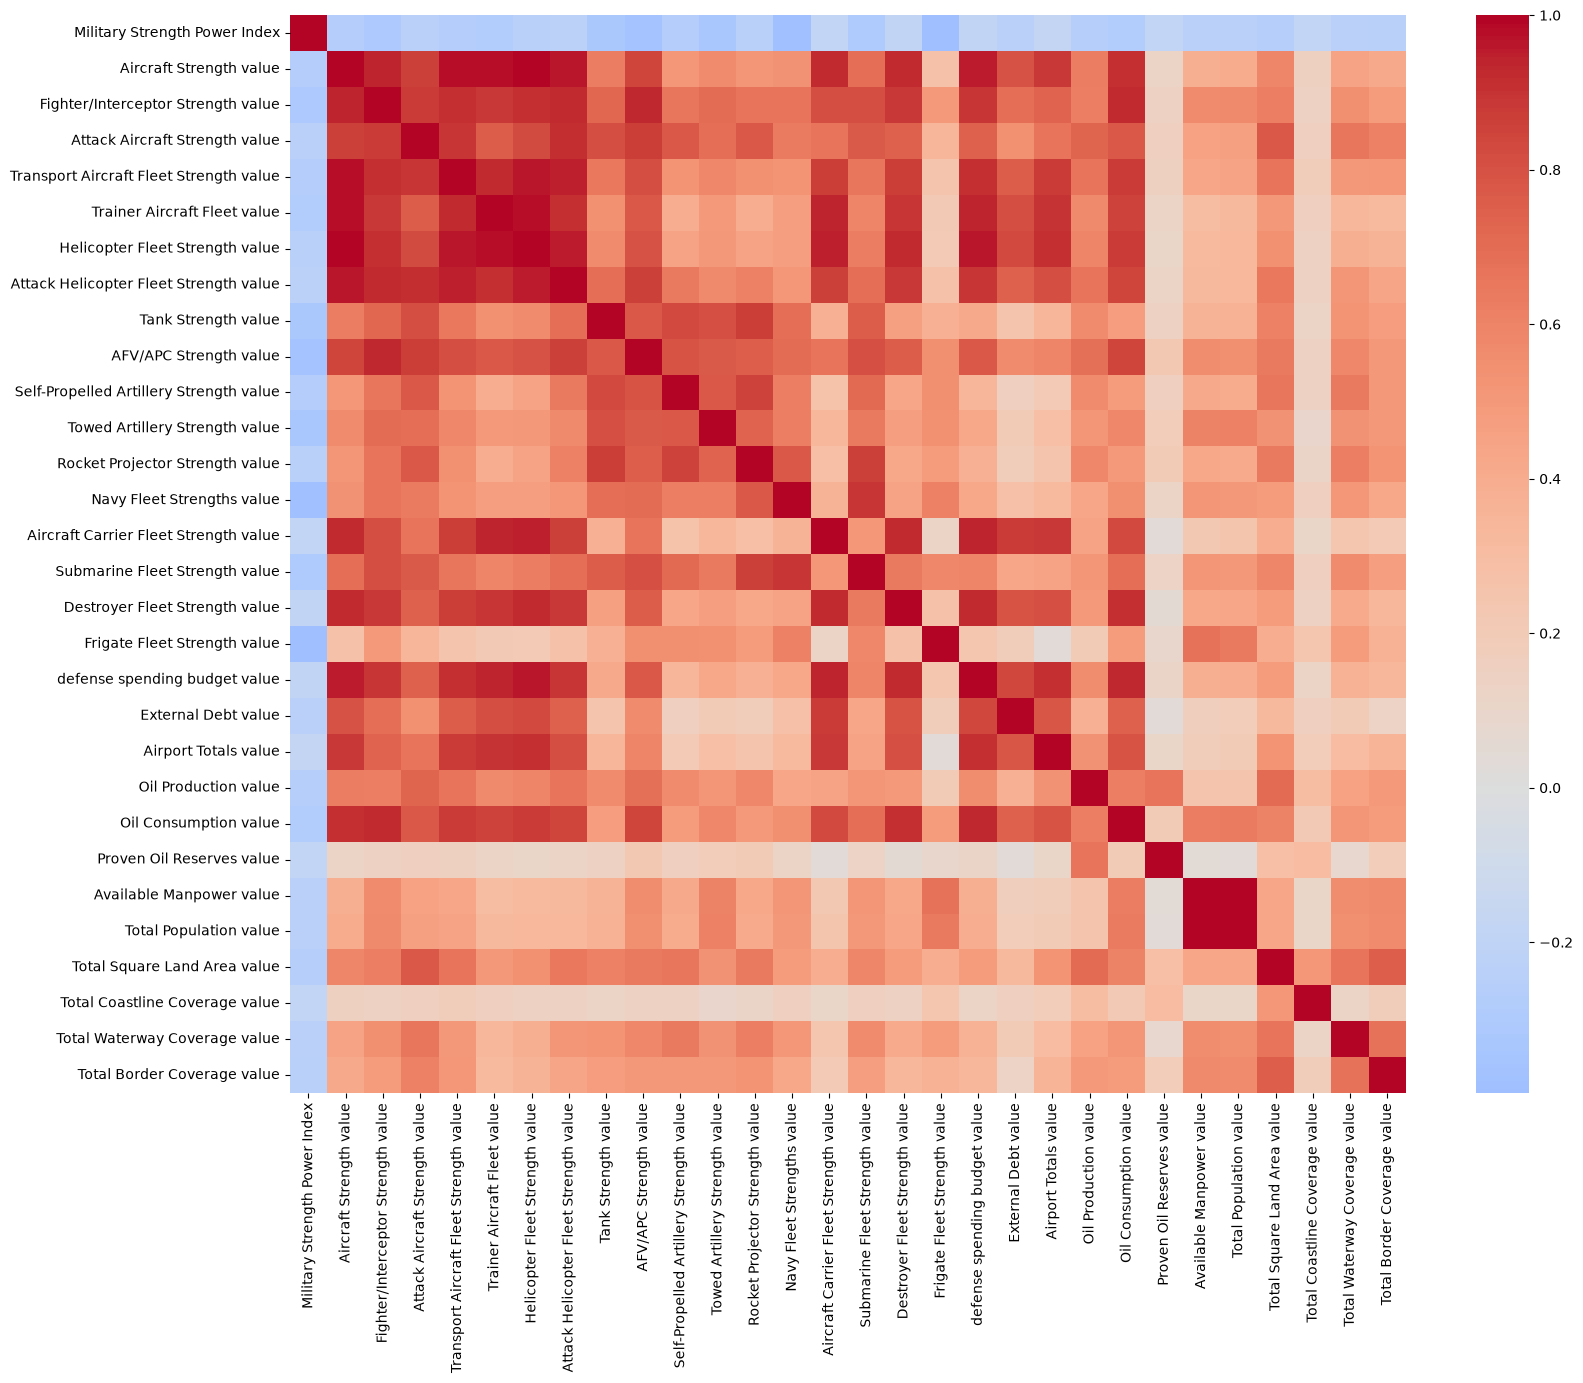

In [34]:
plt.figure(figsize=(18, 14))
sns.heatmap(df.corr(numeric_only=True), cmap="coolwarm", center=0)
plt.show()

The Military Strength Power Index was excluded from the clustering features because it is a composite score derived from the other indicators and is negatively correlated with all of them (a lower index means a stronger military); it will be used later only as a reference to validate the clusters.

In [35]:
X = df.drop(columns=['Country', 'Military Strength Power Index'])
X.skew().sort_values(ascending=False).head(10)

defense spending budget value              9.959267
Airport Totals value                       9.844767
Aircraft Carrier Fleet Strength value      9.771993
Helicopter Fleet Strength value            9.496533
Total Coastline Coverage value             9.077172
Trainer Aircraft Fleet value               9.035121
Aircraft Strength value                    8.789333
Transport Aircraft Fleet Strength value    7.950963
Attack Helicopter Fleet Strength value     7.882558
Destroyer Fleet Strength value             7.849599
dtype: float64

### 3. Clustering

In [36]:
X_log = np.log1p(X)
X_scaled = StandardScaler().fit_transform(X_log)


In [37]:
X_log.skew()

Aircraft Strength value                   -0.151953
Fighter/Interceptor Strength value         0.119659
Attack Aircraft Strength value             0.913036
Transport Aircraft Fleet Strength value    0.302677
Trainer Aircraft Fleet value              -0.187451
Helicopter Fleet Strength value            0.110108
Attack Helicopter Fleet Strength value     0.682444
Tank Strength value                       -0.549581
AFV/APC Strength value                    -0.304694
Self-Propelled Artillery Strength value    0.211841
Towed Artillery Strength value            -0.588271
Rocket Projector Strength value            0.101312
Navy Fleet Strengths value                -0.343805
Aircraft Carrier Fleet Strength value      4.446919
Submarine Fleet Strength value             1.708376
Destroyer Fleet Strength value             3.765596
Frigate Fleet Strength value               0.992239
defense spending budget value             -0.029278
External Debt value                        0.442501
Airport Tota

In [38]:
wcss = []
ss = []
for k in range(2, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    wcss.append(model.inertia_)
    ss1=silhouette_score(X_scaled, labels)
    ss.append(ss1)
    print(ss1)

0.2888867464875352
0.24529120686417968
0.16503301722310304
0.12921347401166877
0.12945715769686053
0.1078875203526308
0.10414999130227257
0.11163473217218663
0.12319082383711814


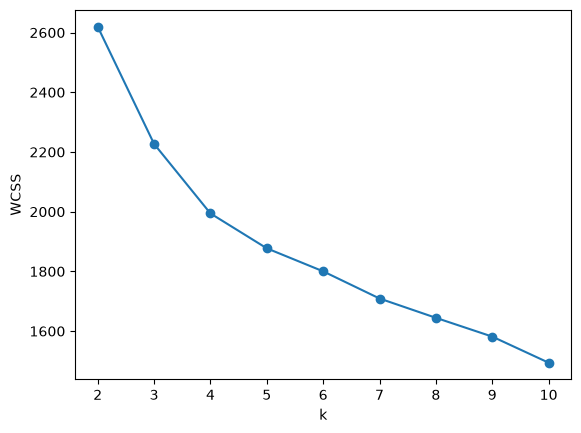

In [39]:
plt.plot(range(2, 11), wcss, marker="o")
plt.xlabel("k"); plt.ylabel("WCSS")
plt.show()

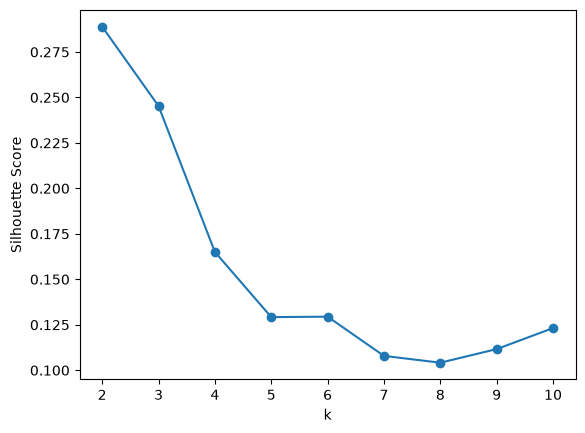

In [40]:
plt.plot(range(2, 11), ss, marker="o")
plt.xlabel("k")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 11))
plt.show()

In [41]:
final_model = KMeans(n_clusters=3, random_state=42, n_init=10)
df["Cluster"] = final_model.fit_predict(X_scaled)

In [42]:
print(silhouette_score(X_scaled, df["Cluster"]))

0.24529120686417968


In [43]:
df["Cluster"].value_counts().sort_index()

Cluster
0    55
1    73
2    10
Name: count, dtype: int64

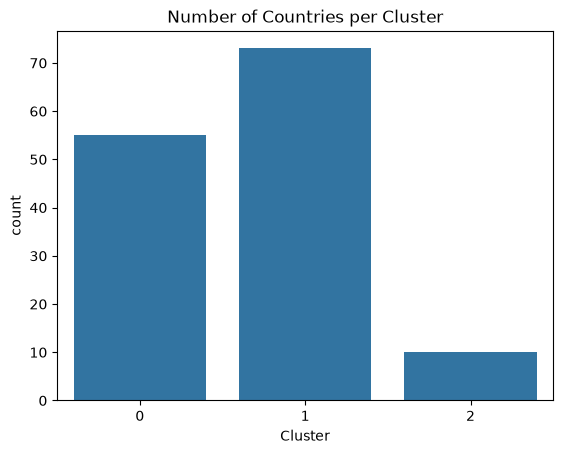

In [44]:
sns.countplot(x=df["Cluster"])
plt.title("Number of Countries per Cluster")
plt.show()

In [45]:
profile_cols = ['Military Strength Power Index', 'Aircraft Strength value', 'Tank Strength value',
                'Navy Fleet Strengths value', 'Submarine Fleet Strength value',
                'defense spending budget value', 'Available Manpower value', 'Total Population value']
df.groupby('Cluster')[profile_cols].median().round(2)

,Military Strength Power Index,Aircraft Strength value,Tank Strength value,Navy Fleet Strengths value,Submarine Fleet Strength value,defense spending budget value,Available Manpower value,Total Population value
Cluster,,,,,,,,
0,0.62,276.0,420.0,63.0,2.0,5.050000e+09,15201837.0,31331228.0
1,2.01,33.0,44.0,8.0,0.0,3.470000e+08,3106010.0,7025763.0
2,0.15,1605.0,3057.0,267.0,18.0,4.850000e+10,48410178.0,112790736.5


In [46]:
cluster_names = {0: 'Regional Powers', 1: 'Limited Capacity', 2: 'Major Powers'}
df['Cluster_Name'] = df['Cluster'].map(cluster_names)

In [47]:
for name in ['Major Powers', 'Regional Powers', 'Limited Capacity']:
    countries = df[df['Cluster_Name'] == name].sort_values('Military Strength Power Index')['Country'].tolist()
    print(f'{name} ({len(countries)}):\n{", ".join(countries)}\n')

Major Powers (10):
United States, Russia, China, India, Japan, South Korea, France, United Kingdom, Egypt, Italy

Regional Powers (55):
Brazil, Turkey, Germany, Iran, Pakistan, Indonesia, Saudi Arabia, Israel, Australia, Spain, Poland, Vietnam, Thailand, Canada, North Korea, Taiwan, Ukraine, Algeria, South Africa, Norway, Sweden, Greece, Myanmar, Netherlands, Colombia, Mexico, Romania, Peru, Venezuela, Nigeria, Argentina, Malaysia, United Arab Emirates, Bangladesh, Chile, Philippines, Denmark, Iraq, Singapore, Uzbekistan, Belarus, Syria, Angola, Morocco, Finland, Bulgaria, Kazakhstan, Azerbaijan, Ecuador, Jordan, Cuba, Yemen, Oman, Sudan, Libya

Limited Capacity (73):
Switzerland, Czechia, Hungary, Slovakia, Ethiopia, Portugal, Serbia, Austria, Bolivia, Croatia, Belgium, Democratic Republic of the Congo, Turkmenistan, Afghanistan, New Zealand, Tunisia, Sri Lanka, Lithuania, Kenya, Kuwait, Uganda, Chad, Zambia, Georgia, Qatar, Zimbabwe, Guatemala, Bahrain, Tajikistan, Uruguay, Mali, Bur

### 4.Conclusion

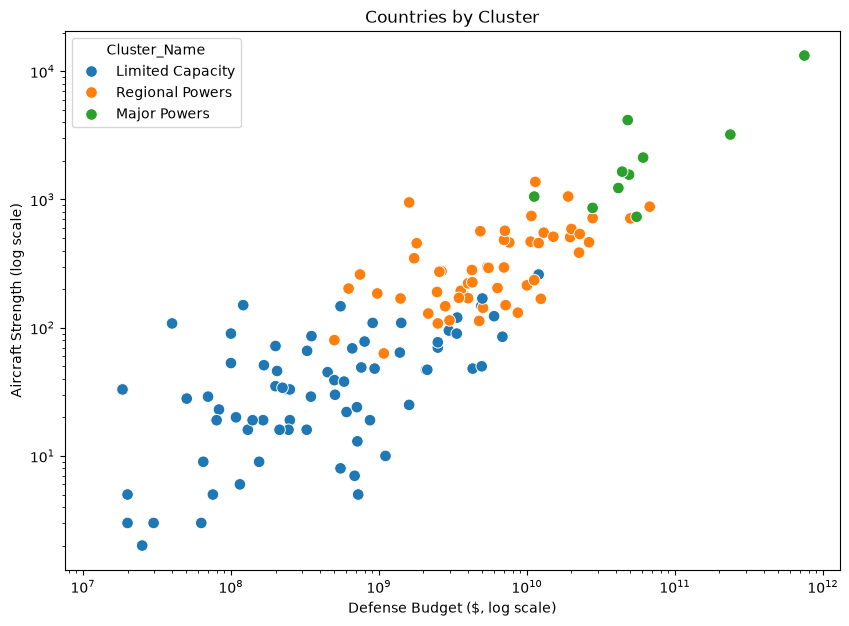

In [48]:
plt.figure(figsize=(10, 7))
sns.scatterplot(data=df, x='defense spending budget value', y='Aircraft Strength value',
                hue='Cluster_Name', s=70)
plt.xscale('log'); plt.yscale('log')
plt.xlabel('Defense Budget ($, log scale)'); plt.ylabel('Aircraft Strength (log scale)')
plt.title('Countries by Cluster')
plt.show()

This project grouped 138 countries by military capability using K-Means clustering on 28 indicators covering air, land and naval forces, defense spending, manpower, natural resources and geography (2020 data).

**Data preparation.** A row misalignment that had placed South Korea's naval data in South Sudan's row was corrected. Missing values were structural rather than random: naval and coastline values were missing for landlocked countries, and border length was missing for island nations, so these were filled with 0. Because the variables were highly right-skewed (skewness up to 10), a log transformation was applied before standardization. The Military Strength Power Index was excluded from the features, since it is a composite score strongly correlated with the other indicators, and was used afterwards only to validate the results.

**Results.** Based on the elbow method and silhouette scores, k = 3 was selected (silhouette = 0.245). It offered the best balance between statistical fit and interpretability:

- **Major Powers (10 countries):** United States, Russia, China, India, Japan, South Korea, France, United Kingdom, Egypt and Italy. The median country has 1,605 aircraft, 3,057 tanks, 18 submarines and a defense budget of $48.5 bn.
- **Regional Powers (55 countries):** e.g. Brazil, Turkey, Germany, Iran, Pakistan and Indonesia. Their capacity is roughly one-tenth that of the Major Powers (276 aircraft, 420 tanks, $5.05 bn budget).
- **Limited Capacity (73 countries):** e.g. Switzerland, Portugal, Kenya and Somalia. This group has the smallest militaries (33 aircraft, 44 tanks, no submarines, $0.35 bn budget).

The Power Index, which was not used in the model, follows the same order (medians 0.15, 0.62 and 2.01). This independently confirms that the clusters reflect real differences in military capacity.

**Limitations.**
- The silhouette score is relatively low, which suggests that countries form a continuum rather than sharply separated groups. The Limited Capacity cluster in particular is heterogeneous (Power Index from 0.53 to 10.17).
- The model includes size-related variables such as population, land area and coastline. As a result, small but wealthy countries (e.g. Switzerland, Belgium, Qatar) are grouped with countries that have far weaker militaries.
- The data counts equipment but does not capture its quality or technology. This explains why Egypt, with its large inventory of tanks and armored vehicles, falls among the Major Powers while Germany is classified as a Regional Power.

**Further work.** Future analyses could cluster on military variables only, use per-capita or per-GDP indicators to reduce the effect of country size, or test alternative methods such as hierarchical clustering.